## Just some basic EDA and a how-to guide. ##

In [6]:
# %load_ext cudf.pandas # Load CUDF
import re
import os
from pathlib import Path
import kagglehub

# Download latest version

# "magic" command to make plots show up in the notebook
%matplotlib inline
filepath = Path(kagglehub.dataset_download("wordsforthewise/lending-club"))

print("Path to dataset files:", filepath)

Path to dataset files: C:\Users\Dell\.cache\kagglehub\datasets\wordsforthewise\lending-club\versions\3


Kaggle changed they way they handle compressed files sometime in 2018.  They automatically uncompress them, and put them in a folder with the same name as the file (but all lowercased).  Here is where they are:

In [7]:
folders = os.listdir(filepath)
# Skip .xslx file, if we are ever able to upload it...
# Currently can't upload due to conflicts with other versions of the dataset on Kaggle.
folders = [f for f in folders if 'xlsx' not in f]
folders

['accepted_2007_to_2018q4.csv',
 'accepted_2007_to_2018Q4.csv.gz',
 'rejected_2007_to_2018q4.csv',
 'rejected_2007_to_2018Q4.csv.gz']

In [8]:
accepted_fn = filepath / 'accepted_2007_to_2018q4.csv' / 'accepted_2007_to_2018Q4.csv'

rejected_fn =  filepath / 'rejected_2007_to_2018q4.csv' / 'rejected_2007_to_2018Q4.csv'

accepted_fn.exists(), rejected_fn.exists()

(True, True)

In [9]:
try:
    import cudf as pd
    BACKEND = "cudf (GPU)"
except Exception:  # ImportError, or CUDA/driver errors on GPU-less machines
    import pandas as pd
    BACKEND = "pandas (CPU)"

print(f"Using {BACKEND}")


acc_df = pd.read_csv(accepted_fn,nrows=500000)
# Takes a while to read, because these files are large...give it a minute or so
# acc_df = pd.read_csv(accepted_fn)

# this is a dataset with rejected loans from lendingclub

acc_df

ModuleNotFoundError: No module named 'pandas'

In [ ]:

rej_df = pd.read_csv(rejected_fn,nrows=500000)
rej_df

,Amount Requested,Application Date,Loan Title,Risk_Score,Debt-To-Income Ratio,Zip Code,State,Employment Length,Policy Code
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10%,481xx,NM,4 years,0.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10%,010xx,MA,< 1 year,0.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10%,212xx,MD,1 year,0.0
3,6000.0,2007-05-27,waksman,698.0,38.64%,017xx,MA,< 1 year,0.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43%,209xx,MD,< 1 year,0.0
...,...,...,...,...,...,...,...,...,...
499995,8000.0,2012-05-01,major_purchase,675.0,14.36%,103xx,NY,< 1 year,0.0
499996,35000.0,2012-05-01,other,675.0,30.91%,085xx,NJ,< 1 year,0.0
499997,4500.0,2012-05-01,home_improvement,0.0,0%,631xx,MO,< 1 year,0.0
499998,10000.0,2012-05-01,home_improvement,649.0,41.96%,219xx,MD,< 1 year,0.0


In [ ]:
REJECTED_CONVERT_COLUMNS = {
    "Amount Requested": "loan_amnt",        # requested amount
    "Application Date": "issue_d",          # loan issue month
    "Loan Title": "title",                  # free-text title (not the category "purpose")
    "Risk_Score": "fico_range_low",         # accepted loans store a FICO range (low/high); pick one bound
    "Debt-To-Income Ratio": "dti",
    "Zip Code": "zip_code",
    "State": "addr_state",
    "Employment Length": "emp_length_str",
    "Policy Code": "policy_code",
    "debt_income_ratio": "dti",             # derived duplicate of Debt-To-Income Ratio
    "employment_lenght_years": "emp_length",  # numeric version of Employment Length
}
rej_df = rej_df.rename(columns=REJECTED_CONVERT_COLUMNS)
rej_df


,loan_amnt,issue_d,title,fico_range_low,dti,zip_code,addr_state,emp_length_str,policy_code
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10%,481xx,NM,4 years,0.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10%,010xx,MA,< 1 year,0.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10%,212xx,MD,1 year,0.0
3,6000.0,2007-05-27,waksman,698.0,38.64%,017xx,MA,< 1 year,0.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43%,209xx,MD,< 1 year,0.0
...,...,...,...,...,...,...,...,...,...
499995,8000.0,2012-05-01,major_purchase,675.0,14.36%,103xx,NY,< 1 year,0.0
499996,35000.0,2012-05-01,other,675.0,30.91%,085xx,NJ,< 1 year,0.0
499997,4500.0,2012-05-01,home_improvement,0.0,0%,631xx,MO,< 1 year,0.0
499998,10000.0,2012-05-01,home_improvement,649.0,41.96%,219xx,MD,< 1 year,0.0


In [ ]:
def percent_to_float(col: pd.Series):
    return col.str.removesuffix("%").astype("float64")
rej_df["dti"] = percent_to_float(rej_df["dti"])
rej_df

,loan_amnt,issue_d,title,fico_range_low,dti,zip_code,addr_state,emp_length_str,policy_code
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10.00,481xx,NM,4 years,0.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10.00,010xx,MA,< 1 year,0.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10.00,212xx,MD,1 year,0.0
3,6000.0,2007-05-27,waksman,698.0,38.64,017xx,MA,< 1 year,0.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43,209xx,MD,< 1 year,0.0
...,...,...,...,...,...,...,...,...,...
499995,8000.0,2012-05-01,major_purchase,675.0,14.36,103xx,NY,< 1 year,0.0
499996,35000.0,2012-05-01,other,675.0,30.91,085xx,NJ,< 1 year,0.0
499997,4500.0,2012-05-01,home_improvement,0.0,0.00,631xx,MO,< 1 year,0.0
499998,10000.0,2012-05-01,home_improvement,649.0,41.96,219xx,MD,< 1 year,0.0


In [ ]:

EMPLOYMENT_LENGTH_TO_YEARS = {
    "< 1 year": 1,
    "1 year": 1,
    "2 years": 2,
    "3 years": 3,
    "4 years": 4,
    "5 years": 5,
    "6 years": 6,
    "7 years": 7,
    "8 years": 8,
    "9 years": 9,
    "10+ years": 11,
}

def employment_length_to_years(employment_length: pd.Series) -> pd.Series:
    """Convert an 'Employment Length' column to numeric years.

    '< 1 year' -> 1, 'N years' -> N, '10+ years' -> 11.
    NaN (and any unknown value) stays null.
    """
    return employment_length.map(EMPLOYMENT_LENGTH_TO_YEARS)
rej_df["emp_length"] = employment_length_to_years(rej_df["emp_length_str"])
rej_df

,loan_amnt,issue_d,title,fico_range_low,dti,zip_code,addr_state,emp_length_str,policy_code,emp_length
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10.00,481xx,NM,4 years,0.0,4.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10.00,010xx,MA,< 1 year,0.0,1.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10.00,212xx,MD,1 year,0.0,1.0
3,6000.0,2007-05-27,waksman,698.0,38.64,017xx,MA,< 1 year,0.0,1.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43,209xx,MD,< 1 year,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
499995,8000.0,2012-05-01,major_purchase,675.0,14.36,103xx,NY,< 1 year,0.0,1.0
499996,35000.0,2012-05-01,other,675.0,30.91,085xx,NJ,< 1 year,0.0,1.0
499997,4500.0,2012-05-01,home_improvement,0.0,0.00,631xx,MO,< 1 year,0.0,1.0
499998,10000.0,2012-05-01,home_improvement,649.0,41.96,219xx,MD,< 1 year,0.0,1.0


In [ ]:
rej_df.dtypes

,0
loan_amnt,float64
issue_d,object
title,object
fico_range_low,float64
dti,float64
zip_code,object
addr_state,object
emp_length_str,object
policy_code,float64
emp_length,float64


In [ ]:
rej_df.describe()

,loan_amnt,fico_range_low,dti,policy_code,emp_length
count,5.000000e+05,479294.000000,5.000000e+05,500000.0,494547.000000
mean,1.223684e+04,584.546906,1.370361e+03,0.0,2.233403
std,1.013681e+04,187.871457,7.358651e+04,0.0,2.745392
min,5.000000e+02,0.000000,-1.000000e+00,0.0,1.000000
25%,4.500000e+03,557.000000,4.020000e+00,0.0,1.000000
50%,1.000000e+04,643.000000,1.581000e+01,0.0,1.000000
75%,2.000000e+04,688.000000,2.990000e+01,0.0,1.000000
max,1.400000e+06,849.000000,5.000003e+07,0.0,11.000000


In [ ]:
rej_df.dropna()

,loan_amnt,issue_d,title,fico_range_low,dti,zip_code,addr_state,emp_length_str,policy_code,emp_length
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10.00,481xx,NM,4 years,0.0,4.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10.00,010xx,MA,< 1 year,0.0,1.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10.00,212xx,MD,1 year,0.0,1.0
3,6000.0,2007-05-27,waksman,698.0,38.64,017xx,MA,< 1 year,0.0,1.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43,209xx,MD,< 1 year,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
499995,8000.0,2012-05-01,major_purchase,675.0,14.36,103xx,NY,< 1 year,0.0,1.0
499996,35000.0,2012-05-01,other,675.0,30.91,085xx,NJ,< 1 year,0.0,1.0
499997,4500.0,2012-05-01,home_improvement,0.0,0.00,631xx,MO,< 1 year,0.0,1.0
499998,10000.0,2012-05-01,home_improvement,649.0,41.96,219xx,MD,< 1 year,0.0,1.0


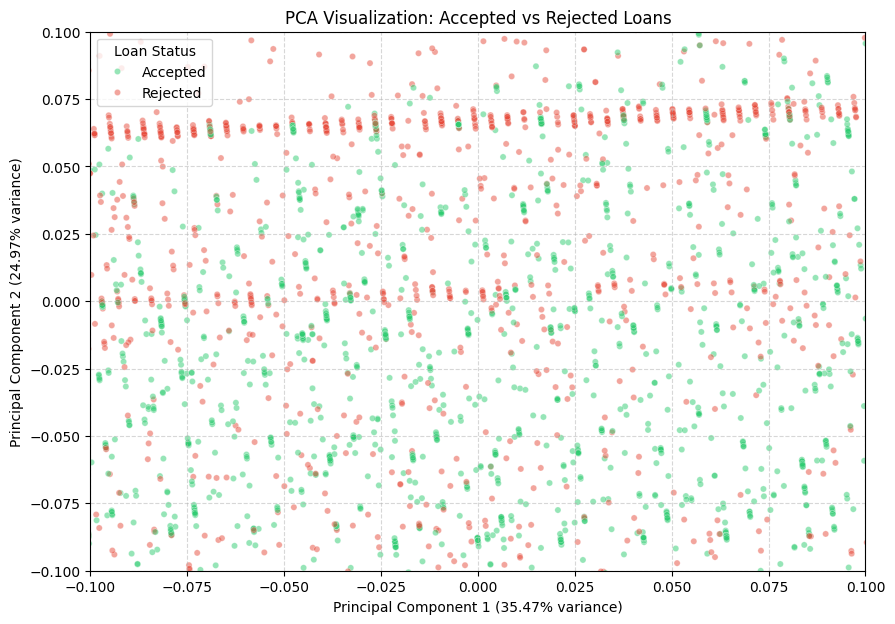

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Employment length dictionary and conversion function
EMPLOYMENT_LENGTH_TO_YEARS = {
    "< 1 year": 1,
    "1 year": 1,
    "2 years": 2,
    "3 years": 3,
    "4 years": 4,
    "5 years": 5,
    "6 years": 6,
    "7 years": 7,
    "8 years": 8,
    "9 years": 9,
    "10+ years": 11,
}


def employment_length_to_years(employment_length: pd.Series) -> pd.Series:
  return employment_length.map(EMPLOYMENT_LENGTH_TO_YEARS)


selected_columns = [
    "loan_amnt",
    "fico_range_low",
    "dti",
    #"policy_code",
    "emp_length",
]

# Prepare rejected loans data (rej_df)
rej_subset = rej_df[selected_columns].copy()
# Note: rejected dataset uses 'emp_length_str' or 'emp_length' depending on your preprocessing steps
rej_emp_col = (
    "emp_length_str" if "emp_length_str" in rej_df.columns else "emp_length"
)
rej_subset["emp_length"] = employment_length_to_years(rej_df[rej_emp_col])
rej_subset = rej_subset.dropna().astype(float)
rej_subset["Status"] = "Rejected"

# Prepare accepted loans data (acc_df)
acc_subset = acc_df[selected_columns].copy()
acc_subset["emp_length"] = employment_length_to_years(acc_subset["emp_length"])
acc_subset = acc_subset.dropna().astype(float)
acc_subset["Status"] = "Accepted"

# Combine both datasets and take a random sample (e.g., 50,000 rows) for faster plotting
combined_df = pd.concat([acc_subset, rej_subset], ignore_index=True)
if len(combined_df) > 50000:
  combined_df = combined_df.sample(n=50000, random_state=42)

# Separate features and status column
X = combined_df[selected_columns]
y_status = combined_df["Status"]

# 2. Scale the data (StandardScaler)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(X)

# 3. Apply PCA (reduce to 2 principal components)
pca = PCA(n_components=2)
pca_transformed = pca.fit_transform(scaled_data)

# 4. Prepare dataframe for visualization
viz_df = pd.DataFrame(pca_transformed, columns=["PC1", "PC2"])
viz_df["Status"] = y_status.values

# 5. Visualization with custom colors for Accepted (Green) vs. Rejected (Red)
status_palette = {"Accepted": "#2ecc71", "Rejected": "#e74c3c"}

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x="PC1",
    y="PC2",
    hue="Status",
    palette=status_palette,
    data=viz_df,
    alpha=0.5,
    s=20,
)

plt.title("PCA Visualization: Accepted vs Rejected Loans")
plt.xlabel(
    f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)"
)
plt.ylabel(
    f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)"
)
plt.legend(title="Loan Status")
plt.grid(True, linestyle="--", alpha=0.5)

plt.xlim(-0.1, 0.1)
plt.ylim(-0.1, 0.1)
plt.show()

In [ ]:
import plotly.express as px

def show_correlation_matrix(df: pd.DataFrame, method: str = "pearson") -> cudf.DataFrame:
    """Compute and display the correlation matrix between the numeric variables of a cuDF DataFrame."""
    numeric_df = df.select_dtypes(include="number")
    corr = numeric_df.corr(method=method)  # computed on GPU, returns a cuDF DataFrame

    fig = px.imshow(
        corr.to_pandas(),                      # plotly needs host data
        text_auto=".2f",                       # annotate each cell
        zmin=-1, zmax=1,
        color_continuous_scale="RdBu_r",       # red = positive, blue = negative
        title=f"{method.capitalize()} correlation matrix",
        aspect="auto",
    )
    fig.update_layout(coloraxis_colorbar=dict(title="corr"))
    fig.show()

    return corr

show_correlation_matrix(rej_df.dropna())

NameError: name 'cudf' is not defined

In [ ]:
list(rej_df.columns)

In [ ]:
acc_df_compare_rej = acc_df[rej_df.select_dtypes(include="number").columns]
acc_df_compare_rej["emp_length"] = employment_length_to_years(acc_df_compare_rej["emp_length"])
acc_df_compare_rej

In [ ]:
show_correlation_matrix(acc_df_compare_rej.dropna())

In [ ]:
STUDIES_COLUMS = ["loan_amnt", "fico_range_low", "dti", "policy_code", "emp_length"]
IS_ACCEPTED_COLUMN_NAME = "is_accepted"

rej_df[IS_ACCEPTED_COLUMN_NAME] = 0
acc_df_compare_rej[IS_ACCEPTED_COLUMN_NAME] = 1

In [ ]:
rej_df.dtypes

In [ ]:
acc_df[[IS_ACCEPTED_COLUMN_NAME] + STUDIES_COLUMS].dtypes

In [ ]:

all_df = pd.concat((rej_df[[IS_ACCEPTED_COLUMN_NAME] + STUDIES_COLUMS],acc_df_compare_rej[[IS_ACCEPTED_COLUMN_NAME] + STUDIES_COLUMS]))
all_df

In [ ]:
show_correlation_matrix(all_df.dropna())

In [ ]:
rej_df.shape

In [ ]:
[col for col in acc_df.columns if 'fico' in col.lower()]

In [ ]:
# No fico score in rejected loans
[col for col in rej_df.columns if 'fico' in col.lower()]

In [ ]:
rej_df.info()

In [ ]:
acc_df.info()

In [ ]:
# this is how many rows pandas will show by default with methods like pd.dataframe.head()
pd.options.display.max_rows

In [ ]:
# we want to increase it, because in this case there are a lot of column names
pd.options.display.max_rows = 1000

In [ ]:
# the .T is transposing the matrix.
# We do this so the 111 column dataframe is easier to read (easier to scroll down than sideways)
# .head() shows the first few rows of the data
acc_df.head().T

In [ ]:
# .tail() shows the last few rows
acc_df.tail().T

In [ ]:
# .info() tells us the datatype(int64, `object` is a string)
# and will also tell us the number of non-null (not missing) data points for each column
# because this dataframe is so large, we have to force it to show the datatypes and non-null numbers with the arguments
acc_df.info(verbose=True, null_counts=True)

# Some common pandas functions

We find ourselves doing the same types of things often in pandas.  For example, masking.  

## Masking dataframes

Maybe we only want to see one column.  We do this like

`acc_df['int_rate']`

We can also subset a dataframe based on some critereon.  Let's look at only the highest interest rates

`acc_df[acc_df['int_rate'] > 20]`

We can take the mean, median, get the standard deviation of columns:

`acc_df['int_rate'].mean()`

In [ ]:
# shows some common summary statistics
# again, transposing with .T to make it easier to read
acc_df.describe().T

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
# "magic" command to make plots show up in the notebook
%matplotlib inline

In [ ]:
acc_df[acc_df['int_rate'] > 20]['int_rate'].mean()
# thats a bit of a complicated statement.  Breaking it down:
# acc_df['int_rate'] > 20 returns a mask: an array of True/False values
# putting this array into acc_df[] returns the dataframe rows where the interest rates are greater than 20

# so this first part: acc_df[acc_df['int_rate'] > 20]
# gives us a dataframe

# we select a column with ['int_rate'] at the end.  Then we get the average value with .mean()

## Finding unique values

Numpy has a function for finding the unique values in an array:

np.unique(array)

This is built into pandas:

acc_df['grade'].unique()

shows us the unique values in that column.

In [ ]:
acc_df['grade'].unique()

In [ ]:
# selecting only grade A loans:
acc_df[acc_df['grade'] == 'A'].describe().T

In [ ]:
acc_df['loan_status'].unique()

In [ ]:
# looking at only defaulted loans:
default_categories = ['Default', 'Charged Off', 'Does not meet the credit policy. Status:Charged Off']
# .isin() is a trick for checking if something is in a list
# it's a pandas-specific function
acc_df[acc_df['loan_status'].isin(default_categories)].describe().T
# check out the average interest rate and dti (debt-to-income)

In [ ]:
# Seaborn is a recently-created Python library for easily making nice-looking plots
# You will have to install it with `conda install seaborn` or `pip install seaborn`, etc

# The docs are here for this function: http://seaborn.pydata.org/generated/seaborn.distplot.html
# Found by Googling 'seaborn histogram'
# Need to drop missing values, otherwise throws an error
# It would be better to impute missing values.
f = sns.distplot(acc_df['dti'].dropna())

In [ ]:
# outliers are screwing up the histogram... remove them
# adapted from http://stackoverflow.com/questions/11686720/is-there-a-numpy-builtin-to-reject-outliers-from-a-list
# we're using interquartile range to determine outliers
def reject_outliers(sr, iq_range=0.5, side='left', return_mask=False):
    """
    Takes an array (or pandas series) and returns an array with outliers excluded, according to the
    interquartile range.

    Parameters:
    -----------
    sr: array
        array of numeric values
    iq_range: float
        percent to calculate quartiles by, 0.5 will yield 25% and 75%ile quartiles
    side: string
        if 'left', will return everything below the highest quartile
        if 'right', will return everything above the lowest quartile
        if 'both', will return everything between the high and low quartiles
    """
    pcnt = (1 - iq_range) / 2
    qlow, median, qhigh = sr.dropna().quantile([pcnt, 0.50, 1-pcnt])
    iqr = qhigh - qlow
    if side=='both':
        mask = (sr - median).abs() <= iqr
    elif side=='left':
        mask = (sr - median) <= iqr
    elif side=='right':
        mask = (sr - median) >= iqr
    else:
        print('options for side are left, right, or both')

    if return_mask:
        return mask

    return sr[mask]

In [ ]:
# sweeeeeeeetttt....
dti_no_outliers = reject_outliers(acc_df['dti'], iq_range=0.85) # arrived at 0.85 via trial and error
f = sns.distplot(dti_no_outliers)
# other types of plot examples:
# http://seaborn.pydata.org/examples/

In [ ]:
# sets the xkcd style if you want to make the plots look funny...may neet to install some fonts
plt.xkcd()

In [ ]:
f = sns.distplot(dti_no_outliers)

In [ ]:
# back to default
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)

In [ ]:
f = sns.distplot(dti_no_outliers)

In [ ]:
# other styles:
# http://matplotlib.org/users/style_sheets.html
# this is the R ggplot style, which some people really like
plt.style.use('ggplot')

In [ ]:
# http://seaborn.pydata.org/generated/seaborn.regplot.html
# takes a long time because there are a lot of points, but works for smaller datasets
# f = sns.regplot(data=acc_df, x='dti', y='int_rate', fit_reg=False)
# instead, lets make a heatmap:
# http://stackoverflow.com/questions/2369492/generate-a-heatmap-in-matplotlib-using-a-scatter-data-set
# http://seaborn.pydata.org/generated/seaborn.jointplot.html
mask = reject_outliers(acc_df['dti'], iq_range=0.85, return_mask=True)
f = sns.jointplot(data=acc_df.ix[mask, :], x='dti', y='int_rate', kind='hex', joint_kws=dict(gridsize=50))

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

class LogicRegr:
  def __init__(self, learning_rate, n_iter):
    self.learning_rate=learning_rate
    self.n_iter= n_iter
    self.w = None
    self.b = None

  def _sigm(self,z):
    z = np.clip(z,-500,500)
    return 1/(1+np.exp(-z))
    
  def fit(self,X,y):
    n_samp,n_feat= X.shape
    self.w = np.zeros(n_feat)
    self.b = 0
    for i in range(self.n_iter):
      linear_model = np.dot(X,self.w)+self.b
      y_predicted = self._sigm(linear_model)
      dw = (1/n_samp)*np.dot(X.T,(y_predicted-y))
      db = (1 / n_samp) * np.sum(y_predicted - y)

      self.w -= self.learning_rate * dw
      self.b -= self.learning_rate * db

  def predict_proba(self, X):
    linear_model = np.dot(X, self.w) + self.b
    return self._sigm(linear_model)

  def predict(self, X, threshold=0.5):
    probabilities = self.predict_proba(X)
    return (probabilities >= threshold).astype(int)



In [ ]:
selected_columns = ["loan_amnt", "fico_range_low", "dti", "emp_length"]

rej_subset = rej_df[selected_columns].copy()
rej_emp_col = (
    "emp_length_str" if "emp_length_str" in rej_df.columns else "emp_length"
)
rej_subset["emp_length"] = employment_length_to_years(rej_df[rej_emp_col])
rej_subset = rej_subset.dropna().astype(float)
rej_subset["Status"] = 0

acc_subset = acc_df[selected_columns].copy()
acc_subset["emp_length"] = employment_length_to_years(acc_subset["emp_length"])
acc_subset = acc_subset.dropna().astype(float)
acc_subset["Status"] = 1

combined_df = pd.concat([acc_subset, rej_subset], ignore_index=True)
if len(combined_df) > 50000:
  combined_df = combined_df.sample(n=50000, random_state=42)

X = combined_df[selected_columns].values
y = combined_df["Status"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

my_model = LogicRegr(learning_rate=0.01, n_iter=100000)
my_model.fit(X_train_scaled, y_train)

y_pred = my_model.predict(X_test_scaled)
accuracy = np.mean(y_pred == y_test)

print(f"Custom Model with Softmax Accuracy: {accuracy:.4f}")
print("Learned Weights:", my_model.w)
print("Learned Bias:", my_model.b)

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

weights_df = pd.DataFrame({"Feature": selected_columns, "Weight": my_model.w})

weights_df = weights_df.sort_values(by="Weight", ascending=True)

plt.figure(figsize=(10, 5))

bar_colors = ["#2ecc71" if w > 0 else "#e74c3c" for w in weights_df["Weight"]]

sns.barplot(
    x="Weight",
    y="Feature",
    data=weights_df,
    hue="Feature",
    palette=bar_colors,
    legend=False,
)

plt.axvline(x=0, color="black", linestyle="--", linewidth=1)

plt.title("Weight")
plt.xlabel("Value")
plt.ylabel("Feature")
plt.grid(True, linestyle="--", alpha=0.3)

plt.show()

In [ ]:

import torch.nn as nn
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid() 
            )
    
    def forward(self, x):
        return self.network(x)

In [ ]:
import torch.optim as optim
import numpy as np


X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

input_dim=X_train_scaled.shape[1]
mlp=MLP(input_dim=input_dim)
criterion = nn.BCELoss()
optimizer = optim.Adam(mlp.parameters(), lr=0.01)

loss_table = []
epochs =500

mlp.train()

for epoch in range(epochs):
  optimizer.zero_grad()
  outputs=mlp(X_train_t)
  loss = criterion(outputs, y_train_t)
  loss.backward()
  optimizer.step()
  if (epoch + 1) % 10 == 0 or epoch == 0:
        loss_table.append({"Epoch": epoch + 1, "Loss": loss.item()})

mlp.eval()
with torch.no_grad():
    test_probabilities = mlp(X_test_t)
    y_pred = (test_probabilities >= 0.5).int().squeeze()
    accuracy = np.mean(y_pred.numpy() == y_test)
print(f"\naccuracy: {accuracy:.4f}")

In [ ]:
loss_df = pd.DataFrame(loss_table)
print("--- history table ---")
print(loss_df.head())

plt.figure(figsize=(8, 4))
plt.plot(loss_df["Epoch"], loss_df["Loss"], label="Training Loss", color="blue", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("value")
plt.grid(True)
plt.legend()
plt.show()